<div dir="rtl">

# 🤖 DemoCheck - מבט ראשון על הנתונים (M1)

**המטרה של המחברת:** לטעון את הנתונים, לראות שהם אמיתיים וקריאים, ולמדוד כמה דברים בסיסיים: כמה הקלטות יש, כמה זמן כל אחת, ואיך נראית תנועה של הרובוט בהקלטה אחת.

**הנתונים:** דגימה מהדאטה-סט הפתוח של Unitree (רובוט G1 עם ידי Inspire, 30 פריימים בשנייה). כדי ליצור אותה מריצים פעם אחת `python scripts/make_sample.py`.

</div>

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("..") / "data"
summary = pd.read_csv(DATA / "episodes_summary.csv")
episode = pd.read_csv(DATA / "sample_episode.csv")

<div dir="rtl">

## 1. טבלת ההקלטות
כל שורה היא הקלטה אחת (אפיזודה): המספר שלה, כמה פריימים יש בה, וכמה שניות היא נמשכה.

</div>

In [2]:
print("מספר הקלטות בקובץ:", len(summary))
summary.head()

מספר הקלטות בקובץ: 19


,episode_index,n_frames,duration_s
0,0,3453,115.066666
1,1,3583,119.400000
2,2,4015,133.800000
3,3,5707,190.200000
4,4,4008,133.566670


<div dir="rtl">

## 2. מדדים בסיסיים

</div>

In [3]:
summary["duration_s"].describe().round(1)

count     19.0
mean     169.4
std       40.6
min      115.1
25%      132.1
50%      163.8
75%      203.1
max      251.8
Name: duration_s, dtype: float64

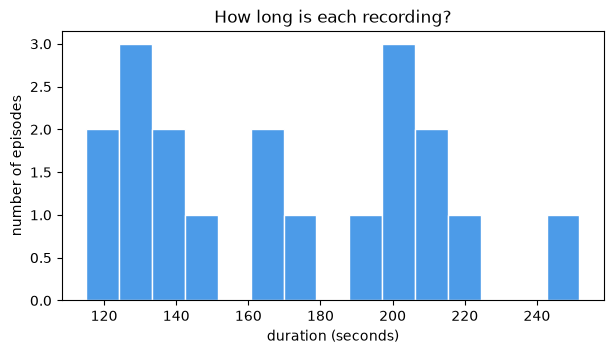

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(summary["duration_s"], bins=15, color="#4C9BE8", edgecolor="white")
ax.set_xlabel("duration (seconds)")
ax.set_ylabel("number of episodes")
ax.set_title("How long is each recording?")
plt.show()

<div dir="rtl">

**מסקנה:** כל ההקלטות הן אותה משימה, ובכל זאת המשך נע בין 115 ל-252 שניות (חציון 164). הקלטה אחת לוקחת פי 2 מאחרת, ולכן משך ההקלטה הוא מועמד טוב למאפיין שיבדיל בין הקלטה חלקה להקלטה עם היסוסים.

</div>

<div dir="rtl">

## 3. הקלטה אחת מבפנים
כל שורה היא פריים אחד (1/30 שנייה). העמודות: זמן, 7 זוויות מפרקים בכל זרוע (ברדיאנים), ו-6 ערכים לכל יד שמתארים כמה כל אצבע סגורה.

</div>

In [5]:
print("פריימים:", len(episode), " | עמודות:", episode.shape[1])
print("חוסרים בהקלטה:", int(episode.isna().sum().sum()))
episode.head()

פריימים: 3453  | עמודות: 29
חוסרים בהקלטה: 0


,episode_index,frame_index,timestamp,left_arm_shoulder_pitch,left_arm_shoulder_roll,left_arm_shoulder_yaw,left_arm_elbow,left_arm_wrist_yaw,left_arm_wrist_roll,left_arm_wrist_pitch,...,left_fig6d_index,left_fig6d_middle,left_fig6d_ring,left_fig6d_little,right_fig6d_thumb_oc,right_fig6d_thumb_lat,right_fig6d_index,right_fig6d_middle,right_fig6d_ring,right_fig6d_little
0,0,0,0.000000,0.094568,0.304507,-0.159642,0.458576,-0.398571,-0.133504,-0.038781,...,1.0,0.998,0.999,0.998,0.901,0.0,0.998,0.999,0.998,0.999
1,0,1,0.033333,0.088935,0.304603,-0.153326,0.455820,-0.422180,-0.133600,-0.040746,...,1.0,0.998,0.999,0.998,0.901,0.0,0.998,0.999,0.998,0.999
2,0,2,0.066667,0.088240,0.306832,-0.151888,0.455868,-0.426147,-0.132689,-0.044282,...,1.0,0.998,0.999,0.998,0.901,0.0,0.998,0.999,0.998,0.999
3,0,3,0.100000,0.090541,0.308043,-0.153027,0.455904,-0.425092,-0.129801,-0.047853,...,1.0,0.998,0.999,0.998,0.901,0.0,0.998,0.999,0.998,0.999
4,0,4,0.133333,0.093453,0.307515,-0.156526,0.456215,-0.425464,-0.128543,-0.048093,...,1.0,0.998,0.999,0.998,0.901,0.0,0.998,0.999,0.998,0.999


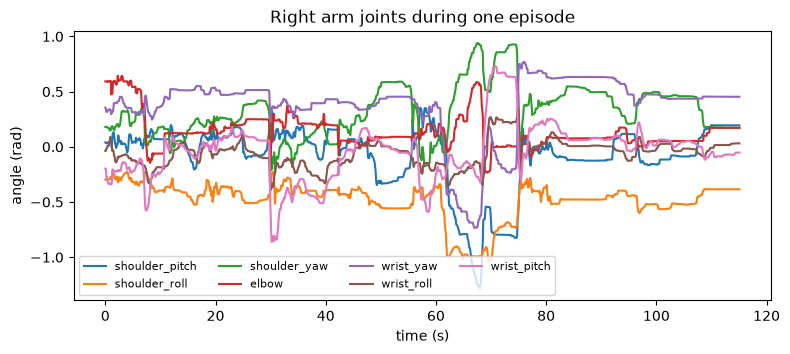

In [6]:
arm = [c for c in episode.columns if c.startswith("right_arm_")]
fig, ax = plt.subplots(figsize=(9, 3.5))
for c in arm:
    ax.plot(episode["timestamp"], episode[c], label=c.replace("right_arm_", ""))
ax.set_xlabel("time (s)")
ax.set_ylabel("angle (rad)")
ax.set_title("Right arm joints during one episode")
ax.legend(fontsize=8, ncol=4)
plt.show()

<div dir="rtl">

**מסקנה:** רוב הזמן הזרוע זזה בתנועות קטנות, והתנועה הגדולה מרוכזת בין שנייה 60 לשנייה 75. כנראה זה השלב שבו הרובוט מושיט יד ומרים את החפץ. כלומר, אפשר לראות שלבים של המשימה מתוך זוויות המפרקים בלבד.

</div>

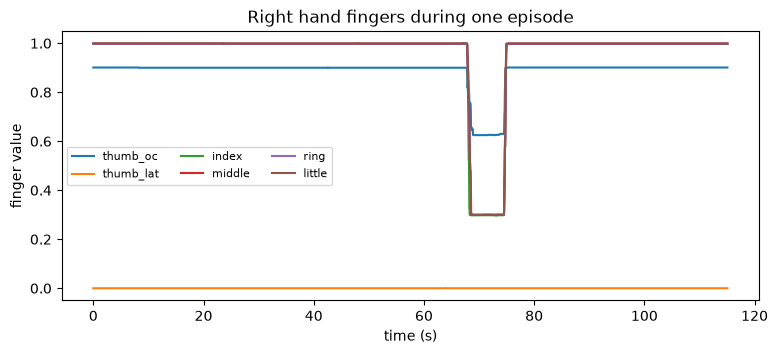

In [7]:
hand = [c for c in episode.columns if c.startswith("right_fig6d_")]
fig, ax = plt.subplots(figsize=(9, 3.5))
for c in hand:
    ax.plot(episode["timestamp"], episode[c], label=c.replace("right_fig6d_", ""))
ax.set_xlabel("time (s)")
ax.set_ylabel("finger value")
ax.set_title("Right hand fingers during one episode")
ax.legend(fontsize=8, ncol=3)
plt.show()

<div dir="rtl">

**מסקנה:** האצבעות כמעט כל הזמן על ערך קרוב ל-1, ויורדות ל-0.3 רק פעם אחת, בערך בין שנייה 67 לשנייה 75, בדיוק כשהזרוע זזה הכי הרבה. זו כנראה אחיזה אחת ברורה. בהקלטה עם היסוסים נצפה לראות כמה ירידות כאלה, וזה מאפיין שקל לספור. thumb_lat קבוע על 0, כנראה לא בשימוש במשימה הזו.

</div>

<div dir="rtl">

## 4. סיכום ומה הלאה
**מה מדדנו:** 19 הקלטות בקובץ הראשון (מתוך 200 בדאטה-סט), 30 פריימים בשנייה, 0 חוסרים בהקלטה שבדקנו. הנתונים נפתחים ב-Python רגיל (pandas), בלי SDK של Unitree.

**מה חסר:** בנתונים הפתוחים אין תיוג הצלחה/כישלון. ה-y יגיע מההקלטות של המעבדה.

**הצעד הבא (M2):** להחליף את הדגימה הפתוחה בהקלטות מהמעבדה, שבהן לכל הקלטה יש תיוג הצליח/נכשל, ולחשב לכל הקלטה מאפיינים (משך, מהירות, זמן אחיזה, מספר פתיחות וסגירות של היד).

</div>